# EDA-MISSING DATA HANDLING

in exploratory data analysis(EDA),handling missing values is a crucial step to ensure that the dataset is clean and reliable for analysis and modeling.misssing values can skew results or make some analysis impossible,so it's essential to identify and handle them effectively

# identify missing values

*check for missing values:this can be done by using methods like isnull()or isna()in python with return a boolian mask where missing values are  marked as true.

*summary of missing data:use methods like info()to get a concise summary of the dataset,or isnull().sum()to count the number of missing values per column

# Handling missing values

a) removing missing data
 *remove rows:if only a few rows contain missing values you can drop them using dropna().this is useful when the dataset is large,and losing a small portion of data wont have a significant impact
 *remove columns:if an entire column has too many missing values (eg.more than 550-60%missing),consider dropping the column especially if its not importent for your analysis

b) imputing missing data
 *mean/median/mode imputation:replace missing values with the mean,median,mode of the column this is simple and commonly used for numericcal data

 # df['column'].fillna(df['column'].mean(),inplace=True)#Mean
 # df['column'].fillna(df['column'].median(),inplace=True)#Median
 # df['column'].fillna(df['column'].mode()[0],inplace=True)#Mode

In [2]:
#importing libraries

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
df=pd.read_csv(r"C:\Users\Slim3\Desktop\beer-servings (1).csv")
df

,Unnamed: 0,country,beer_servings,spirit_servings,wine_servings,total_litres_of_pure_alcohol,continent
0,0,Afghanistan,0.0,0.0,0.0,0.0,Asia
1,1,Albania,89.0,132.0,54.0,4.9,Europe
2,2,Algeria,25.0,0.0,14.0,0.7,Africa
3,3,Andorra,245.0,138.0,312.0,12.4,Europe
4,4,Angola,217.0,57.0,45.0,5.9,Africa
...,...,...,...,...,...,...,...
188,188,Venezuela,NaN,100.0,3.0,7.7,South America
189,189,Vietnam,111.0,2.0,1.0,2.0,Asia
190,190,Yemen,6.0,0.0,0.0,0.1,Asia
191,191,Zambia,32.0,19.0,4.0,2.5,Africa


In [4]:
df.head()

,Unnamed: 0,country,beer_servings,spirit_servings,wine_servings,total_litres_of_pure_alcohol,continent
0,0,Afghanistan,0.0,0.0,0.0,0.0,Asia
1,1,Albania,89.0,132.0,54.0,4.9,Europe
2,2,Algeria,25.0,0.0,14.0,0.7,Africa
3,3,Andorra,245.0,138.0,312.0,12.4,Europe
4,4,Angola,217.0,57.0,45.0,5.9,Africa


In [5]:
df.tail()

,Unnamed: 0,country,beer_servings,spirit_servings,wine_servings,total_litres_of_pure_alcohol,continent
188,188,Venezuela,NaN,100.0,3.0,7.7,South America
189,189,Vietnam,111.0,2.0,1.0,2.0,Asia
190,190,Yemen,6.0,0.0,0.0,0.1,Asia
191,191,Zambia,32.0,19.0,4.0,2.5,Africa
192,192,Zimbabwe,64.0,18.0,4.0,4.7,Africa


In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 193 entries, 0 to 192
Data columns (total 7 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   Unnamed: 0                    193 non-null    int64  
 1   country                       193 non-null    str    
 2   beer_servings                 185 non-null    float64
 3   spirit_servings               185 non-null    float64
 4   wine_servings                 187 non-null    float64
 5   total_litres_of_pure_alcohol  192 non-null    float64
 6   continent                     193 non-null    str    
dtypes: float64(4), int64(1), str(2)
memory usage: 10.7 KB


In [7]:
df.columns

Index(['Unnamed: 0', 'country', 'beer_servings', 'spirit_servings',
       'wine_servings', 'total_litres_of_pure_alcohol', 'continent'],
      dtype='str')

In [8]:
df.describe()

,Unnamed: 0,beer_servings,spirit_servings,wine_servings,total_litres_of_pure_alcohol
count,193.000000,185.000000,185.000000,187.000000,192.000000
mean,96.000000,105.124324,83.221622,50.165775,4.741667
std,55.858452,100.524714,89.142958,80.358868,3.767654
min,0.000000,0.000000,0.000000,0.000000,0.000000
25%,48.000000,20.000000,4.000000,1.000000,1.300000
50%,96.000000,76.000000,60.000000,9.000000,4.250000
75%,144.000000,185.000000,132.000000,60.500000,7.200000
max,192.000000,376.000000,438.000000,370.000000,14.400000


In [9]:
df.shape

(193, 7)

In [10]:
df.drop("Unnamed: 0",axis=1,inplace=True)



In [11]:
df

,country,beer_servings,spirit_servings,wine_servings,total_litres_of_pure_alcohol,continent
0,Afghanistan,0.0,0.0,0.0,0.0,Asia
1,Albania,89.0,132.0,54.0,4.9,Europe
2,Algeria,25.0,0.0,14.0,0.7,Africa
3,Andorra,245.0,138.0,312.0,12.4,Europe
4,Angola,217.0,57.0,45.0,5.9,Africa
...,...,...,...,...,...,...
188,Venezuela,NaN,100.0,3.0,7.7,South America
189,Vietnam,111.0,2.0,1.0,2.0,Asia
190,Yemen,6.0,0.0,0.0,0.1,Asia
191,Zambia,32.0,19.0,4.0,2.5,Africa


In [12]:
df.shape

(193, 6)

In [13]:
df.isnull().sum()             #null value detecting

country                         0
beer_servings                   8
spirit_servings                 8
wine_servings                   6
total_litres_of_pure_alcohol    1
continent                       0
dtype: int64

In [14]:
df.isna().sum()  

country                         0
beer_servings                   8
spirit_servings                 8
wine_servings                   6
total_litres_of_pure_alcohol    1
continent                       0
dtype: int64

In [15]:
df.dtypes

country                             str
beer_servings                   float64
spirit_servings                 float64
wine_servings                   float64
total_litres_of_pure_alcohol    float64
continent                           str
dtype: object

use fillna function

check the data types in info 

float - use mean or median by checking through histogram

in histogram,if there is skewness we can use median/use mean if no skewness 

object-use mode ()[0]


In [16]:
freqgraph=df.select_dtypes(include='float')
freqgraph

,beer_servings,spirit_servings,wine_servings,total_litres_of_pure_alcohol
0,0.0,0.0,0.0,0.0
1,89.0,132.0,54.0,4.9
2,25.0,0.0,14.0,0.7
3,245.0,138.0,312.0,12.4
4,217.0,57.0,45.0,5.9
...,...,...,...,...
188,NaN,100.0,3.0,7.7
189,111.0,2.0,1.0,2.0
190,6.0,0.0,0.0,0.1
191,32.0,19.0,4.0,2.5


array([[<Axes: title={'center': 'beer_servings'}>,
        <Axes: title={'center': 'spirit_servings'}>],
       [<Axes: title={'center': 'wine_servings'}>,
        <Axes: title={'center': 'total_litres_of_pure_alcohol'}>]],
      dtype=object)

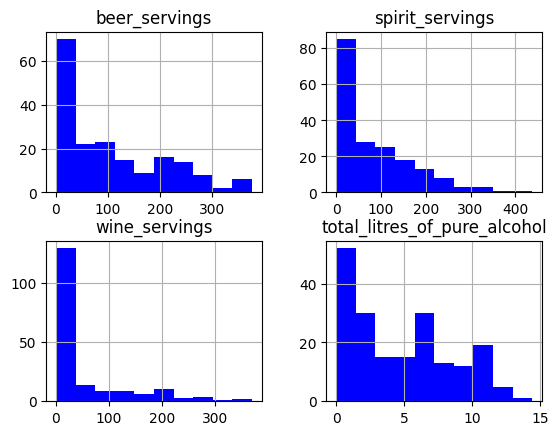

In [17]:
freqgraph.hist(color='b')

## **Graphs are skewed so use median to fill na values**

>skewness in a measurement of the distortion of symmetrical distribution or asymmetrical in data set.skewness is demonstrated on a bell curve when data points are not distributed symmetrically to the left and right sides of the median on a bell curve

In [18]:
df.columns

Index(['country', 'beer_servings', 'spirit_servings', 'wine_servings',
       'total_litres_of_pure_alcohol', 'continent'],
      dtype='str')

In [19]:
df['beer_servings']=df['beer_servings'].fillna(df['beer_servings'].median())
df['beer_servings']


0        0.0
1       89.0
2       25.0
3      245.0
4      217.0
       ...  
188     76.0
189    111.0
190      6.0
191     32.0
192     64.0
Name: beer_servings, Length: 193, dtype: float64

In [20]:
df['beer_servings'].isna().sum()

np.int64(0)

In [21]:
for i in ['beer_servings','spirit_servings','wine_servings',
          'total_litres_of_pure_alcohol']:
        df[i]=df[i].fillna(df[i].median())    

df[i]

0       0.0
1       4.9
2       0.7
3      12.4
4       5.9
       ... 
188     7.7
189     2.0
190     0.1
191     2.5
192     4.7
Name: total_litres_of_pure_alcohol, Length: 193, dtype: float64

In [22]:
df.isna().sum()

country                         0
beer_servings                   0
spirit_servings                 0
wine_servings                   0
total_litres_of_pure_alcohol    0
continent                       0
dtype: int64

# OUTLIER REMOVAL

## BOX PLOT

a box plot also known as a box-and-whisker plot,is a graphical representation of the distribution of a dataset.it displays the data's minimum first quartile(Q1),median(Q2),third quartile(Q3),and maximum values.the "box"in the box plot shows the interquartile range (IQR),which represents the middle 50% of the data while the "whiskers"extend to the minimum and maximum values excluding any outliers

## components of a box plot:

>box:represents the middle 50% of the data(from Q1 to Q3)
>WHISKERS:extend to the smallest and largest values within 1.5 times the IQR from Q1 and Q3, respectively
>outliers:points outside the whiskers are considered potential outliers
>median(Q2):the line inside the box represents the median(50th percentile)of the data

## outlier

an outlier is a data point that siffers  significantly from the rest of the dataset.outliers can occur due to variability in the data or errors in measurment.they can skew the result of statistical analyses,so it's important to identify and potentially remove them to get a clearer understanding of the data

qutliers are data points that faill outside the whiskers.typically any values more than 1.5 times the IQR below the first quartile or above the third quartile is considered an outlier

## why use box plot for outlier removal?

A box plot is a simple, visual tool to identify outliers. It highlights values that fall outside the "whiskers," helping to easily detect potential outliers that could affect the analysis. By identifying these outliers, you can decide whether to:
- **Remove them** to prevent skewing your analysis.
- **Analyze them further** to determine if they represent genuine, unusual behavior or if they are errors.

 Q1, Q2, and Q3
 --
- **Q1 (First Quartile)**: This is the 25th percentile of the data. It marks the value below which 25% of the data falls. It represents the lower boundary of the box in the box plot.
- **Q2 (Second Quartile or Median)**: This is the 50th percentile, meaning it divides the dataset into two equal halves. It is represented by the line inside the box and is the middle value when the data is sorted.
- **Q3 (Third Quartile)**: This is the 75th percentile of the data. It marks the value below which 75% of the data falls. It represents the upper boundary of the box in the box plot.

 IQR (Interquartile Range)
 ---
- The **IQR** is the range between the first quartile (Q1) and the third quartile (Q3) and represents the spread of the middle 50% of the data. The IQR is calculated as:
  IQR = Q3 - Q1
  
 Outlier Detection Using IQR
 ---
Outliers can be identified using the following rules:
- **Below Q1 - 1.5 * IQR**: Values below this range are considered outliers.
- **Above Q3 + 1.5 * IQR**: Values above this range are considered outliers.





# finding outliers

## box plot is used for outlier detection

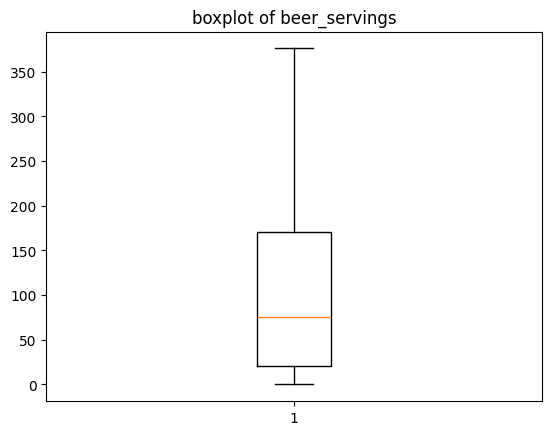

In [23]:
plt.boxplot(df['beer_servings'])
plt.title('boxplot of beer_servings');

# outlier removal of spirit servings

In [24]:
Q1 =np.percentile(df['spirit_servings'],25,method='midpoint')
Q2 =np.percentile(df['spirit_servings'],50,method='midpoint')
Q3 =np.percentile(df['spirit_servings'],75,method='midpoint')

print(Q1)
print(Q2)
print(Q3)

5.0
60.0
128.0


In [25]:
df['spirit_servings'].median()

np.float64(60.0)

In [26]:
IQR=Q3-Q1
print(IQR)

123.0


In [27]:
upper_limit=Q3+1.5*IQR
lower_limit=Q1-1.5*IQR
print(lower_limit)
print(upper_limit)

-179.5
312.5


In [28]:
outlier=[]
for x in df['spirit_servings']:
  if((x>upper_limit) or (x<lower_limit)):
    outlier.append(x)
outlier

[373.0, 438.0, 326.0, 326.0, 315.0]

In [29]:
df1=df['spirit_servings']>upper_limit
df1


0      False
1      False
2      False
3      False
4      False
       ...  
188    False
189    False
190    False
191    False
192    False
Name: spirit_servings, Length: 193, dtype: bool

In [30]:
df.loc[df1]

,country,beer_servings,spirit_servings,wine_servings,total_litres_of_pure_alcohol,continent
15,Belarus,142.0,373.0,42.0,14.4,Europe
68,Grenada,199.0,438.0,28.0,11.9,North America
73,Haiti,1.0,326.0,1.0,5.9,North America
141,Russian Federation,247.0,326.0,73.0,11.5,Asia
144,St. Lucia,171.0,315.0,71.0,10.1,North America


In [31]:
df.loc[df1].index

Index([15, 68, 73, 141, 144], dtype='int64')

In [32]:
df.drop([15, 68, 73, 141, 144],inplace=True)

In [33]:
df.head(20)

,country,beer_servings,spirit_servings,wine_servings,total_litres_of_pure_alcohol,continent
0,Afghanistan,0.0,0.0,0.0,0.00,Asia
1,Albania,89.0,132.0,54.0,4.90,Europe
2,Algeria,25.0,0.0,14.0,0.70,Africa
3,Andorra,245.0,138.0,312.0,12.40,Europe
4,Angola,217.0,57.0,45.0,5.90,Africa
5,Antigua & Barbuda,102.0,128.0,45.0,4.90,North America
6,Argentina,76.0,25.0,221.0,8.30,South America
7,Armenia,21.0,179.0,11.0,3.80,Europe
8,Australia,261.0,72.0,212.0,10.40,Oceania
9,Austria,279.0,75.0,191.0,9.70,Europe


In [34]:
df.reset_index()

,index,country,beer_servings,spirit_servings,wine_servings,total_litres_of_pure_alcohol,continent
0,0,Afghanistan,0.0,0.0,0.0,0.0,Asia
1,1,Albania,89.0,132.0,54.0,4.9,Europe
2,2,Algeria,25.0,0.0,14.0,0.7,Africa
3,3,Andorra,245.0,138.0,312.0,12.4,Europe
4,4,Angola,217.0,57.0,45.0,5.9,Africa
...,...,...,...,...,...,...,...
183,188,Venezuela,76.0,100.0,3.0,7.7,South America
184,189,Vietnam,111.0,2.0,1.0,2.0,Asia
185,190,Yemen,6.0,0.0,0.0,0.1,Asia
186,191,Zambia,32.0,19.0,4.0,2.5,Africa


In [35]:
df.shape

(188, 6)

In [36]:
outlier=[]
for x in df['spirit_servings']:
  if((x<lower_limit) or (x>upper_limit)):
    outlier.append(x)
outlier

[]

In [37]:
Q1 = np.percentile(df['beer_servings'], 25, method='midpoint')
Q2 = np.percentile(df['beer_servings'], 50, method='midpoint')
Q3 = np.percentile(df['beer_servings'], 75, method='midpoint')

print(Q1)
print(Q2)
print(Q3)

21.0
76.0
168.0


In [38]:
df['beer_servings'].median()

np.float64(76.0)

In [39]:
IQR=Q3-Q1
print(IQR)

147.0


In [40]:
upper_limit=Q3+1.5*IQR
lower_limit=Q1-1.5*IQR
print(lower_limit)
print(upper_limit)

-199.5
388.5


In [41]:
outlier=[]
for x in df['beer_servings']:
  if((x>upper_limit) or (x<lower_limit)):
    outlier.append(x)
outlier

[]

In [42]:
Q1 = np.percentile(df['wine_servings'], 25, method='midpoint')
Q2 = np.percentile(df['wine_servings'], 50, method='midpoint')
Q3 = np.percentile(df['wine_servings'], 75, method='midpoint')

print(Q1)
print(Q2)
print(Q3)

1.0
9.0
57.5


In [43]:
df['wine_servings'].median()

np.float64(9.0)

In [44]:
IQR=Q3-Q1
print(IQR)

56.5


In [45]:
upper_limit=Q3+1.5*IQR
lower_limit=Q1-1.5*IQR
print(lower_limit)
print(upper_limit)

-83.75
142.25


In [46]:
outlier=[]
for x in df['beer_servings']:
  if((x>upper_limit) or (x<lower_limit)):
    outlier.append(x)
outlier

[245.0,
 217.0,
 261.0,
 279.0,
 143.0,
 295.0,
 263.0,
 167.0,
 173.0,
 245.0,
 231.0,
 144.0,
 147.0,
 240.0,
 149.0,
 230.0,
 192.0,
 361.0,
 224.0,
 193.0,
 162.0,
 224.0,
 263.0,
 347.0,
 346.0,
 234.0,
 313.0,
 281.0,
 343.0,
 236.0,
 149.0,
 238.0,
 376.0,
 251.0,
 203.0,
 188.0,
 169.0,
 306.0,
 285.0,
 213.0,
 163.0,
 343.0,
 194.0,
 297.0,
 194.0,
 283.0,
 157.0,
 196.0,
 270.0,
 225.0,
 284.0,
 152.0,
 185.0,
 197.0,
 206.0,
 219.0,
 249.0]

In [47]:
df1=df['wine_servings']>upper_limit
df1

0      False
1      False
2      False
3       True
4      False
       ...  
188    False
189    False
190    False
191    False
192    False
Name: wine_servings, Length: 188, dtype: bool

In [48]:
df.loc[df1]

,country,beer_servings,spirit_servings,wine_servings,total_litres_of_pure_alcohol,continent
3,Andorra,245.0,138.0,312.0,12.4,Europe
6,Argentina,76.0,25.0,221.0,8.3,South America
8,Australia,261.0,72.0,212.0,10.4,Oceania
9,Austria,279.0,75.0,191.0,9.7,Europe
16,Belgium,295.0,84.0,212.0,10.5,Europe
35,Chile,130.0,124.0,172.0,7.6,South America
42,Croatia,230.0,87.0,254.0,10.2,Europe
48,Denmark,224.0,81.0,278.0,10.4,Europe
55,Equatorial Guinea,92.0,0.0,233.0,5.8,Africa
61,France,127.0,151.0,370.0,11.8,Europe


In [49]:
df.loc[df1].index

Index([  3,   6,   8,   9,  16,  35,  42,  48,  55,  61,  64,  65,  67,  75,
        81,  83,  99, 120, 121, 136, 140, 156, 165, 166, 182, 185],
      dtype='int64')

In [50]:
df.drop([3,6,8,9,16,35,42,48,  55,  61,  64,  65,  67,  75,
        81,  83,  99, 120, 121, 136, 140, 156, 165, 166, 182, 185],inplace=True)

In [51]:
df.head(20)

,country,beer_servings,spirit_servings,wine_servings,total_litres_of_pure_alcohol,continent
0,Afghanistan,0.0,0.0,0.0,0.00,Asia
1,Albania,89.0,132.0,54.0,4.90,Europe
2,Algeria,25.0,0.0,14.0,0.70,Africa
4,Angola,217.0,57.0,45.0,5.90,Africa
5,Antigua & Barbuda,102.0,128.0,45.0,4.90,North America
7,Armenia,21.0,179.0,11.0,3.80,Europe
10,Azerbaijan,21.0,46.0,5.0,1.30,Europe
11,Bahamas,122.0,176.0,51.0,6.30,North America
12,Bahrain,42.0,63.0,7.0,2.00,Asia
13,Bangladesh,76.0,60.0,9.0,4.25,Asia


In [52]:
df.reset_index()

,index,country,beer_servings,spirit_servings,wine_servings,total_litres_of_pure_alcohol,continent
0,0,Afghanistan,0.0,0.0,0.0,0.0,Asia
1,1,Albania,89.0,132.0,54.0,4.9,Europe
2,2,Algeria,25.0,0.0,14.0,0.7,Africa
3,4,Angola,217.0,57.0,45.0,5.9,Africa
4,5,Antigua & Barbuda,102.0,128.0,45.0,4.9,North America
...,...,...,...,...,...,...,...
157,188,Venezuela,76.0,100.0,3.0,7.7,South America
158,189,Vietnam,111.0,2.0,1.0,2.0,Asia
159,190,Yemen,6.0,0.0,0.0,0.1,Asia
160,191,Zambia,32.0,19.0,4.0,2.5,Africa


In [53]:
df.shape

(162, 6)

In [54]:
outlier=[]
for x in df['wine_servings']:
  if((x<lower_limit) or (x>upper_limit)):
    outlier.append(x)
outlier

[]

In [55]:
Q1 =np.percentile(df['total_litres_of_pure_alcohol'],25,method='midpoint')
Q2 =np.percentile(df['total_litres_of_pure_alcohol'],50,method='midpoint')
Q3 =np.percentile(df['total_litres_of_pure_alcohol'],75,method='midpoint')

print(Q1)
print(Q2)
print(Q3)

1.0
2.8
6.3


In [56]:
IQR=Q3-Q1
print(IQR)

5.3


In [57]:
upper_limit=Q3+1.5*IQR
lower_limit=Q1-1.5*IQR
print(lower_limit)
print(upper_limit)

-6.949999999999999
14.25


In [58]:
outlier=[]
for x in df['total_litres_of_pure_alcohol']:
  if((x>upper_limit) or (x<lower_limit)):
    outlier.append(x)
outlier

[]

# Data visualisation

<function matplotlib.pyplot.show(close=None, block=None)>

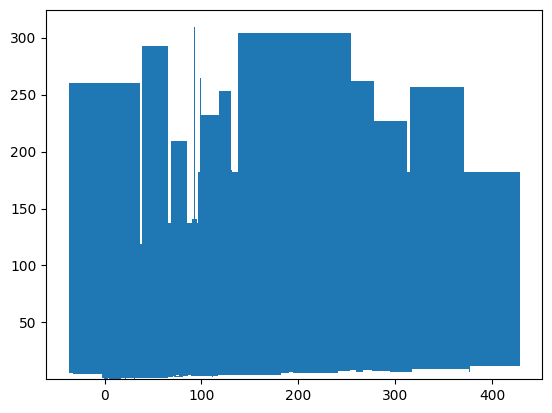

In [59]:
plt.bar(df.beer_servings,df.spirit_servings,df.wine_servings,df.total_litres_of_pure_alcohol)
plt.show

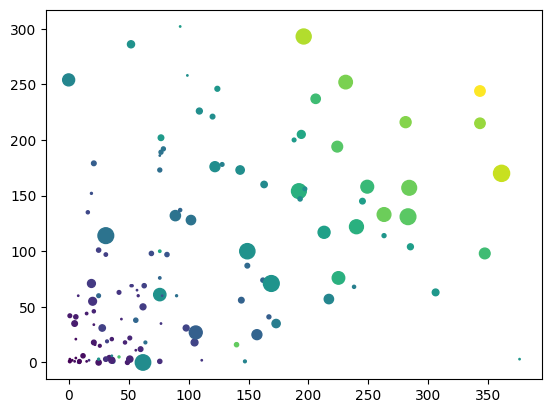

In [75]:
plt.scatter(df.beer_servings,df.spirit_servings,df.wine_servings,df.total_litres_of_pure_alcohol)
plt.show()

C:\Users\Slim3\AppData\Local\Temp\ipykernel_25732\374274262.py:1: MatplotlibDeprecationWarning: Passing the range parameter of hist() positionally is deprecated since Matplotlib 3.10; the parameter will become keyword-only in 3.12.
  plt.hist(df.beer_servings,df.spirit_servings,df.wine_servings,df.total_litres_of_pure_alcohol)


ValueError: The truth value of a Series is ambiguous. Use a.empty, a.bool(), a.item(), a.any() or a.all().

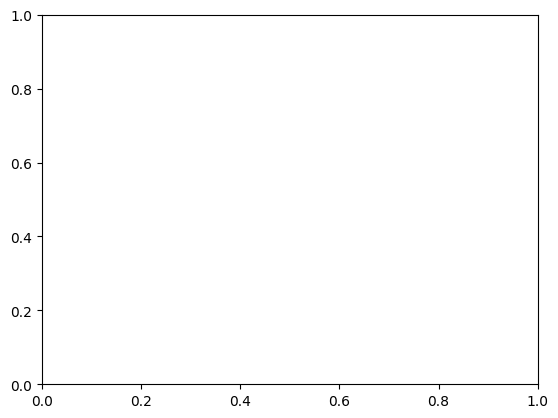

In [76]:
plt.hist(df.beer_servings,df.spirit_servings,df.wine_servings,df.total_litres_of_pure_alcohol)
plt.show()

# ENCODING

In Exploratory Data Analysis (EDA), **encoding** refers to the process of converting categorical data into numerical formats so that machine learning algorithms, which primarily work with numerical values, can interpret and process the data. 


1. **Label Encoding**: This method converts each category in a categorical feature into a unique integer. 
    For example, a feature with categories "red", "blue", and "green" might be encoded as 0, 1, and 2, respectively.
   -  Simple and easy to implement.
   -  Implies an ordinal relationship between the categories, which may not always be appropriate.

2. **One-Hot Encoding**: This technique creates binary (0 or 1) columns for each unique category in a categorical feature.
    For example, a feature with categories "red", "blue", and "green" would be transformed into three new columns: `red`, `blue`, and `green`, where each row has a 1 in the appropriate column and 0 in the others.
   -  Does not impose any ordinal relationship between categories.
   -  Can increase the dimensionality of the dataset if the categorical feature has many unique values.


# One hot encoding

In [60]:
df1=pd.get_dummies(df)

In [61]:
df1.shape

(162, 172)

In [62]:
df.country.nunique()

162

In [63]:
df.continent.nunique()

6

In [64]:
df2=df.drop('country',axis=1,inplace=True)

In [65]:
df1

,beer_servings,spirit_servings,wine_servings,total_litres_of_pure_alcohol,country_Afghanistan,country_Albania,country_Algeria,country_Angola,country_Antigua & Barbuda,country_Armenia,...,country_Vietnam,country_Yemen,country_Zambia,country_Zimbabwe,continent_Africa,continent_Asia,continent_Europe,continent_North America,continent_Oceania,continent_South America
0,0.0,0.0,0.0,0.0,True,False,False,False,False,False,...,False,False,False,False,False,True,False,False,False,False
1,89.0,132.0,54.0,4.9,False,True,False,False,False,False,...,False,False,False,False,False,False,True,False,False,False
2,25.0,0.0,14.0,0.7,False,False,True,False,False,False,...,False,False,False,False,True,False,False,False,False,False
4,217.0,57.0,45.0,5.9,False,False,False,True,False,False,...,False,False,False,False,True,False,False,False,False,False
5,102.0,128.0,45.0,4.9,False,False,False,False,True,False,...,False,False,False,False,False,False,False,True,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
188,76.0,100.0,3.0,7.7,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,True
189,111.0,2.0,1.0,2.0,False,False,False,False,False,False,...,True,False,False,False,False,True,False,False,False,False
190,6.0,0.0,0.0,0.1,False,False,False,False,False,False,...,False,True,False,False,False,True,False,False,False,False
191,32.0,19.0,4.0,2.5,False,False,False,False,False,False,...,False,False,True,False,True,False,False,False,False,False


In [66]:
# df2=pd.get_dummies(df2)

df_1=pd.get_dummies(df1)
df_1

df2=df_1.astype(int)

In [67]:
df2.head()

,beer_servings,spirit_servings,wine_servings,total_litres_of_pure_alcohol,country_Afghanistan,country_Albania,country_Algeria,country_Angola,country_Antigua & Barbuda,country_Armenia,...,country_Vietnam,country_Yemen,country_Zambia,country_Zimbabwe,continent_Africa,continent_Asia,continent_Europe,continent_North America,continent_Oceania,continent_South America
0,0,0,0,0,1,0,0,0,0,0,...,0,0,0,0,0,1,0,0,0,0
1,89,132,54,4,0,1,0,0,0,0,...,0,0,0,0,0,0,1,0,0,0
2,25,0,14,0,0,0,1,0,0,0,...,0,0,0,0,1,0,0,0,0,0
4,217,57,45,5,0,0,0,1,0,0,...,0,0,0,0,1,0,0,0,0,0
5,102,128,45,4,0,0,0,0,1,0,...,0,0,0,0,0,0,0,1,0,0


# Label encoding

In [68]:
df.head()

,beer_servings,spirit_servings,wine_servings,total_litres_of_pure_alcohol,continent
0,0.0,0.0,0.0,0.0,Asia
1,89.0,132.0,54.0,4.9,Europe
2,25.0,0.0,14.0,0.7,Africa
4,217.0,57.0,45.0,5.9,Africa
5,102.0,128.0,45.0,4.9,North America


In [69]:
pip install scikit-learn

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.3 -> 26.1.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [70]:
from sklearn.preprocessing import LabelEncoder

In [71]:
le=LabelEncoder()

In [72]:
df['continent']=le.fit_transform(df['continent'])

In [73]:
df.head()

,beer_servings,spirit_servings,wine_servings,total_litres_of_pure_alcohol,continent
0,0.0,0.0,0.0,0.0,1
1,89.0,132.0,54.0,4.9,2
2,25.0,0.0,14.0,0.7,0
4,217.0,57.0,45.0,5.9,0
5,102.0,128.0,45.0,4.9,3


In [74]:
df2=df.drop('country',axis=1,inplace=True)

KeyError: "['country'] not found in axis"

In [ ]:
df

machine learning model does not take categorical values so encoding required


# SCALING

In [ ]:
# SCALING
# In exploratory data analysis (EDA),scaling refers to the process of adjusting the range of feature values to thye fit with in a specific range or distribution. This is often done to ensure that all features are treated equally by machine learning models.

# # Common Types Of Scaling:

# 1.Min-Max scaling (Normalization):This scales the feature to a fixed range,usually[0,1].

# The formula for Min-Max scaling is:
#      Xscaled = X - Xmin
#                __________
#                Xmax - Xmin

# It maintains the relationships between values but forces them within a specific range.

# 2. Standardization (Z-score scaling): This scales the data so that it has a mean of 0 and a std of 1.The formula is:

# Z=X-Mean
#   _______
#     STD


This method is useful when data follows a normal distribution.

In [ ]:
# Why scaling is important in EDA

# * Improves model performance: Algorithums that calculate distances between data points are sensitive to feature scales. scaling ensures that all features contribute equally.
# * Speeds up covergence: In models like gradient descent scaling can help the algorithm converge faster by eliminating discrepancies in feature ranges.
# * Removes bias: Unscaled data can introduce bias toward featured with larger ranges, potentially skewing the results.

# Scaling is a crucial step in preparing data for models and is often performed after EDA to ensure accurate analysis and model performance.

# MinMAx Scaling

In [ ]:
# Scaling only done for features is values used for predicting,scaling not done on target columns.

In [ ]:
# X=df.drop('total_litres_of_pure_alcohol',axis=)
# Y=df['total_litres_of_pure_alcohole',]
# Z=df['continent']

In [ ]:
x=df.drop(['total_litres_of_pure_alcohol','continent'],axis=1)

In [ ]:
Y=df[['total_litres_of_pure_alcohol','continent']]

In [ ]:
Y

,total_litres_of_pure_alcohol,continent
0,0.0,1
1,4.9,2
2,0.7,0
4,5.9,0
5,4.9,3
...,...,...
188,7.7,5
189,2.0,1
190,0.1,1
191,2.5,0


In [ ]:
from sklearn.preprocessing import MinMaxScaler

In [ ]:
minmax=MinMaxScaler(feature_range=(0,1))

In [ ]:
x1=minmax.fit_transform(x)

In [ ]:
x1

array([[0.        , 0.        , 0.        ],
       [0.23670213, 0.43708609, 0.40298507],
       [0.06648936, 0.        , 0.10447761],
       [0.57712766, 0.18874172, 0.3358209 ],
       [0.2712766 , 0.42384106, 0.3358209 ],
       [0.05585106, 0.59271523, 0.08208955],
       [0.05585106, 0.15231788, 0.03731343],
       [0.32446809, 0.58278146, 0.38059701],
       [0.11170213, 0.20860927, 0.05223881],
       [0.20212766, 0.1986755 , 0.06716418],
       [0.38031915, 0.57284768, 0.26865672],
       [0.69946809, 0.37748344, 0.05970149],
       [0.09042553, 0.01324503, 0.09701493],
       [0.06117021, 0.        , 0.        ],
       [0.44414894, 0.13576159, 0.05970149],
       [0.20212766, 0.57284768, 0.05970149],
       [0.46010638, 0.11589404, 0.26119403],
       [0.65159574, 0.48013245, 0.11940299],
       [0.08244681, 0.00662252, 0.00746269],
       [0.6143617 , 0.83443709, 0.70149254],
       [0.06648936, 0.1986755 , 0.05223881],
       [0.23404255, 0.        , 0.        ],
       [0.

In [ ]:
type(x1)
# now x1 become an array

numpy.ndarray

In [ ]:
df.columns

Index(['beer_servings', 'spirit_servings', 'wine_servings',
       'total_litres_of_pure_alcohol', 'continent'],
      dtype='str')

In [ ]:
x1=pd.DataFrame(x1,columns=['Beer_serving','spirit_serving','wine_servings'])
# Converting x1 back into data frame

In [ ]:
x1

,Beer_serving,spirit_serving,wine_servings
0,0.000000,0.000000,0.000000
1,0.236702,0.437086,0.402985
2,0.066489,0.000000,0.104478
3,0.577128,0.188742,0.335821
4,0.271277,0.423841,0.335821
...,...,...,...
157,0.202128,0.331126,0.022388
158,0.295213,0.006623,0.007463
159,0.015957,0.000000,0.000000
160,0.085106,0.062914,0.029851


In [ ]:
x1.describe()

,Beer_serving,spirit_serving,wine_servings
count,162.000000,162.000000,162.000000
mean,0.230299,0.239208,0.153722
std,0.244585,0.262603,0.248742
min,0.000000,0.000000,0.000000
25%,0.045878,0.009934,0.007463
50%,0.144947,0.142384,0.052239
75%,0.337766,0.399834,0.139925
max,1.000000,1.000000,1.000000


In [ ]:
x2=pd.concat([x1,Y],axis=1)

In [ ]:
x2

,Beer_serving,spirit_serving,wine_servings,total_litres_of_pure_alcohol,continent
0,0.000000,0.000000,0.000000,0.0,1.0
1,0.236702,0.437086,0.402985,4.9,2.0
2,0.066489,0.000000,0.104478,0.7,0.0
3,0.577128,0.188742,0.335821,NaN,NaN
4,0.271277,0.423841,0.335821,5.9,0.0
...,...,...,...,...,...
188,NaN,NaN,NaN,7.7,5.0
189,NaN,NaN,NaN,2.0,1.0
190,NaN,NaN,NaN,0.1,1.0
191,NaN,NaN,NaN,2.5,0.0
